# Network Size (layers and nodes) and the "Tiny Batch Test"

We reuse the plain MLP + Fashion-MNIST training loop (no convolutions). This notebook has two parts.

**Part 1: the tiny batch test.** Before training on all 60,000 images, try to **overfit a tiny batch** (32 images). A correct pipeline *must* be able to drive the loss to about zero and reach 100% accuracy on 32 images. If it can't, something is broken, and it's far cheaper to find out now. We deliberately break the pipeline in several ways and watch the test catch each bug.

**Part 2: network size.** Change the **width** (nodes per layer) and **depth** (number of layers) of the MLP and see how accuracy, overfitting and the ability to memorize change.

## 0. Setup, data and model

In [1]:
import math, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device)

mean, std = 0.2860, 0.3530
tr = datasets.FashionMNIST('data', train=True,  download=True)
te = datasets.FashionMNIST('data', train=False, download=True)

def to_tensors(ds):
    x = (ds.data.float() / 255 - mean) / std
    return x.unsqueeze(1), ds.targets

Xtr, ytr = to_tensors(tr)
Xte, yte = to_tensors(te)
train_ds          = TensorDataset(Xtr, ytr)
train_eval_loader = DataLoader(train_ds, batch_size=1000)
test_loader       = DataLoader(TensorDataset(Xte, yte), batch_size=1000)

PyTorch 2.11.0+cpu | device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.93MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.5MB/s]


In [2]:
class MLP(nn.Module):
    # hidden = tuple of layer widths, e.g. (128, 64) = two hidden layers; () = no hidden layer (linear model)
    def __init__(self, hidden=(128, 64)):
        super().__init__()
        layers, d = [nn.Flatten()], 784
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, 10))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

criterion = nn.CrossEntropyLoss()

for hidden in [(), (16,), (128, 64), (128,) * 4]:
    print(f'hidden={str(hidden):22s} parameters={count_params(MLP(hidden)):>9,}')

hidden=()                     parameters=    7,850
hidden=(16,)                  parameters=   12,730
hidden=(128, 64)              parameters=  109,386
hidden=(128, 128, 128, 128)   parameters=  151,306


## Part 1: The tiny batch test

### Why it works
A network with enough capacity can **memorize** 32 images. So, if you train repeatedly on those same 32 images and the loss does *not* go to about zero, the problem is not "the model isn't good enough". The problem is a **bug**: a missing line, a wrong loss, mismatched labels, a learning rate that is far too small, and so on.

The recipe:
1. Take 32 training examples. Keep them **fixed** (no new data each step).
2. Run the normal training step on them for a few hundred iterations.
3. Expect: loss falls to about 0, accuracy reaches 100%.

### The test, with deliberate bugs

`tiny_batch()` runs the usual 5-step loop on one fixed batch. The `variant` argument breaks it in a specific way:

| Variant | The bug |
|---|---|
| `correct` | nothing: this is the healthy pipeline |
| `no_step` | forgot `optimizer.step()` |
| `no_backward` | forgot `loss.backward()` |
| `tiny_lr` | learning rate is 1e-6 by mistake |
| `double_softmax` | applied `softmax` to the outputs, then passed them to `CrossEntropyLoss` (which applies it again) |
| `shuffled_labels` | images and labels get shuffled *separately* every step (a classic data-loading bug) |

In [3]:
def tiny_batch(variant='correct', steps=300, n=32, lr=0.01, momentum=0.9, hidden=(128, 64), seed=0):
    x, y = Xtr[:n].to(device), ytr[:n].to(device)          # ONE fixed batch, reused every step
    torch.manual_seed(seed)
    model = MLP(hidden).to(device)
    opt = optim.SGD(model.parameters(), lr=(1e-6 if variant == 'tiny_lr' else lr), momentum=momentum)
    losses, accs = [], []
    for _ in range(steps):
        model.train()
        opt.zero_grad()
        out = model(x)
        if variant == 'double_softmax':
            out = torch.softmax(out, dim=1)                # bug: CrossEntropyLoss expects raw logits
        targets = y[torch.randperm(n, device=device)] if variant == 'shuffled_labels' else y
        loss = criterion(out, targets)
        if variant != 'no_backward':
            loss.backward()
        if variant != 'no_step':
            opt.step()
        losses.append(loss.item())
        accs.append((out.argmax(1) == y).float().mean().item())
    return losses, accs

### Predict first

For each variant, will the loss go to about 0? What loss would it get stuck at? (Chance level for 10 classes is `ln 10 = 2.30`.)

| Variant | Loss after 300 steps (guess) | Reaches 100% accuracy? |
|---|---|---|
| correct | | |
| no_step | | |
| no_backward | | |
| tiny_lr | | |
| double_softmax | | |
| shuffled_labels | | |

In [4]:
variants = ['correct', 'no_step', 'no_backward', 'tiny_lr', 'double_softmax', 'shuffled_labels']
tb = {v: tiny_batch(v) for v in variants}

rows = []
for v, (losses, accs) in tb.items():
    rows.append({'variant': v, 'final_loss': losses[-1], 'final_acc': accs[-1],
                 'min_loss': min(losses), 'verdict': 'PASS' if (losses[-1] < 0.1 and accs[-1] == 1.0) else 'FAIL'})
display(pd.DataFrame(rows).set_index('variant').round(4))

,final_loss,final_acc,min_loss,verdict
variant,,,,
correct,0.0022,1.0000,0.0022,PASS
no_step,2.2591,0.2500,2.2591,FAIL
no_backward,2.2591,0.2500,2.2591,FAIL
tiny_lr,2.2552,0.2500,2.2552,FAIL
double_softmax,1.5739,0.9062,1.5739,FAIL
shuffled_labels,2.1740,0.1875,2.1113,FAIL


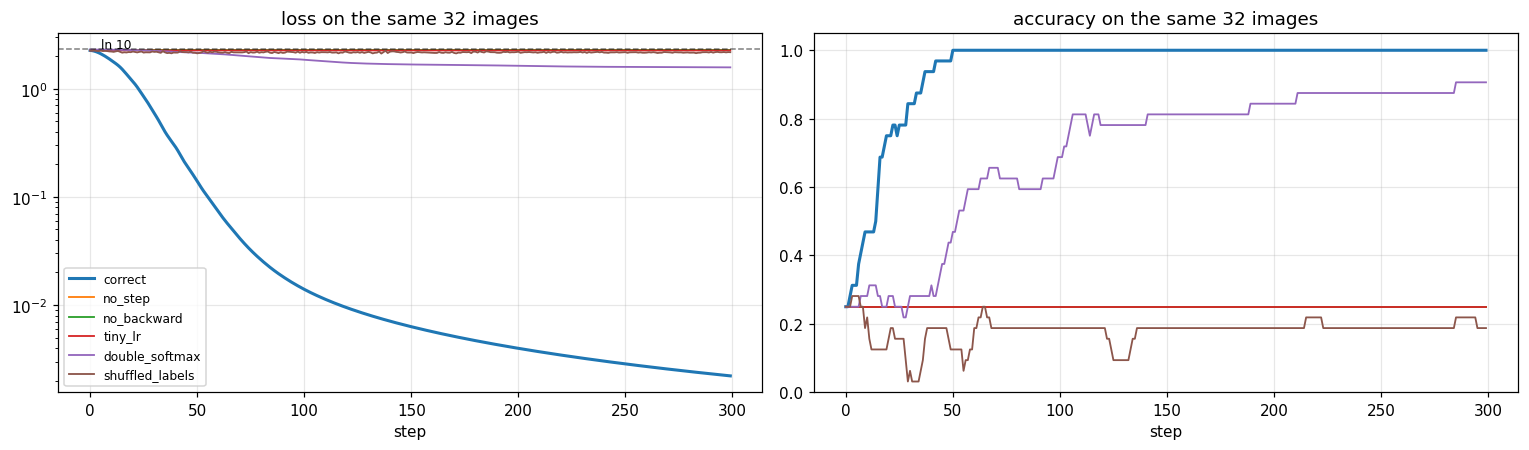

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for v, (losses, accs) in tb.items():
    ax[0].plot(losses, label=v, lw=2 if v == 'correct' else 1.2)
    ax[1].plot(accs,   label=v, lw=2 if v == 'correct' else 1.2)
ax[0].axhline(math.log(10), color='k', ls='--', lw=1, alpha=.5); ax[0].text(5, math.log(10) + .05, 'ln 10', fontsize=8)
ax[0].set_yscale('log'); ax[0].set_title('loss on the same 32 images'); ax[0].set_xlabel('step'); ax[0].legend(fontsize=8)
ax[1].set_title('accuracy on the same 32 images'); ax[1].set_xlabel('step'); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

What the test tells you:
- **correct:** loss collapses toward zero and accuracy hits 100%. The pipeline can learn.
- **no_step / no_backward / tiny_lr:** the loss is flat. The weights are not changing (or barely). Nothing is learning.
- **double_softmax:** the loss *decreases but stalls well above zero*. Softmax outputs live in [0, 1], so the "logits" can never be far apart, and the lowest possible loss is about `ln(1 + 9/e) = 1.46`. A floor that is not zero is a clue.
- **shuffled_labels:** the loss hovers near `ln 10 = 2.30`, since the label attached to each image changes every step, so there is nothing consistent to memorize.

**Use it as a habit:** before every new project, overfit one small batch. It takes seconds, and when it fails, it tells you the bug is in the *pipeline*, not in the amount of data or the hyperparameters.

## Part 2: Network size

Now that we trust the pipeline, vary the architecture. We train each network on the full dataset (batch 128, SGD, lr 0.01, momentum 0.9) and measure train and test accuracy. We also reuse the tiny batch test as a measure of **capacity**: how many steps does each network need to memorize 64 images?

(In a real project you would compare architectures on a *validation* set and keep the test set for the end. Here we report the test set to keep the notebook short.)

In [6]:
EPOCHS = 12

def run(hidden, epochs=EPOCHS, lr=0.01, momentum=0.9, batch_size=128, seed=0):
    torch.manual_seed(seed)
    model = MLP(hidden).to(device)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    opt = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    h = dict(hidden=hidden, params=count_params(model), train_loss=[], train_acc=[], test_loss=[], test_acc=[])
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()                       # 1. clear gradients
            loss = criterion(model(x), y)         # 2-3. forward + loss
            loss.backward()                       # 4. backward
            opt.step()                            # 5. update
        trl, tra = evaluate(model, train_eval_loader)
        tel, tea = evaluate(model, test_loader)
        for k, v in zip(['train_loss', 'train_acc', 'test_loss', 'test_acc'], [trl, tra, tel, tea]):
            h[k].append(v)
    h['time'] = time.time() - t0
    # capacity probe: steps needed to memorize 64 fixed images
    _, accs = tiny_batch('correct', steps=500, n=64, hidden=hidden)
    h['steps_to_memorize_64'] = next((i + 1 for i, a in enumerate(accs) if a == 1.0), None)
    return h

def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total / n, correct / n

### Predict first: width

One hidden layer, with the number of nodes varying: **linear (no hidden layer), 4, 16, 64, 256, 1024**.

| Hidden nodes | Test accuracy (guess) | Train accuracy (guess) |
|---|---|---|
| none (linear) | | |
| 4 | | |
| 16 | | |
| 64 | | |
| 256 | | |
| 1024 | | |

Questions: Where do the returns diminish? Does the biggest network overfit the most?

### Experiment A: width (nodes per layer)

In [7]:
width_cfgs = {'linear (no hidden)': (), '4': (4,), '16': (16,), '64': (64,), '256': (256,), '1024': (1024,)}
width_res = {}
for name, hidden in width_cfgs.items():
    width_res[name] = run(hidden)
    r = width_res[name]
    print(f'{name:20s} params={r["params"]:>9,}  train_acc={r["train_acc"][-1]:.4f}  test_acc={r["test_acc"][-1]:.4f}  ({r["time"]:.0f}s)')

linear (no hidden)   params=    7,850  train_acc=0.8630  test_acc=0.8356  (21s)
4                    params=    3,190  train_acc=0.8240  test_acc=0.8101  (21s)
16                   params=   12,730  train_acc=0.8865  test_acc=0.8574  (21s)
64                   params=   50,890  train_acc=0.9122  test_acc=0.8772  (25s)
256                  params=  203,530  train_acc=0.9276  test_acc=0.8860  (40s)
1024                 params=  814,090  train_acc=0.9369  test_acc=0.8883  (102s)


### Predict first: depth

Fixed width of 128 nodes per layer, with the number of hidden layers varying: **1, 2, 4, 8**. Will more layers keep helping?

### Experiment B: depth (number of layers)

In [8]:
depth_cfgs = {f'{d} layer(s)': (128,) * d for d in [1, 2, 4, 8]}
depth_res = {}
for name, hidden in depth_cfgs.items():
    depth_res[name] = run(hidden)
    r = depth_res[name]
    print(f'{name:12s} params={r["params"]:>9,}  train_acc={r["train_acc"][-1]:.4f}  test_acc={r["test_acc"][-1]:.4f}  ({r["time"]:.0f}s)')

1 layer(s)   params=  101,770  train_acc=0.9216  test_acc=0.8815  (29s)
2 layer(s)   params=  118,282  train_acc=0.9247  test_acc=0.8840  (33s)
4 layer(s)   params=  151,306  train_acc=0.9224  test_acc=0.8797  (39s)
8 layer(s)   params=  217,354  train_acc=0.9059  test_acc=0.8726  (54s)


### Plots

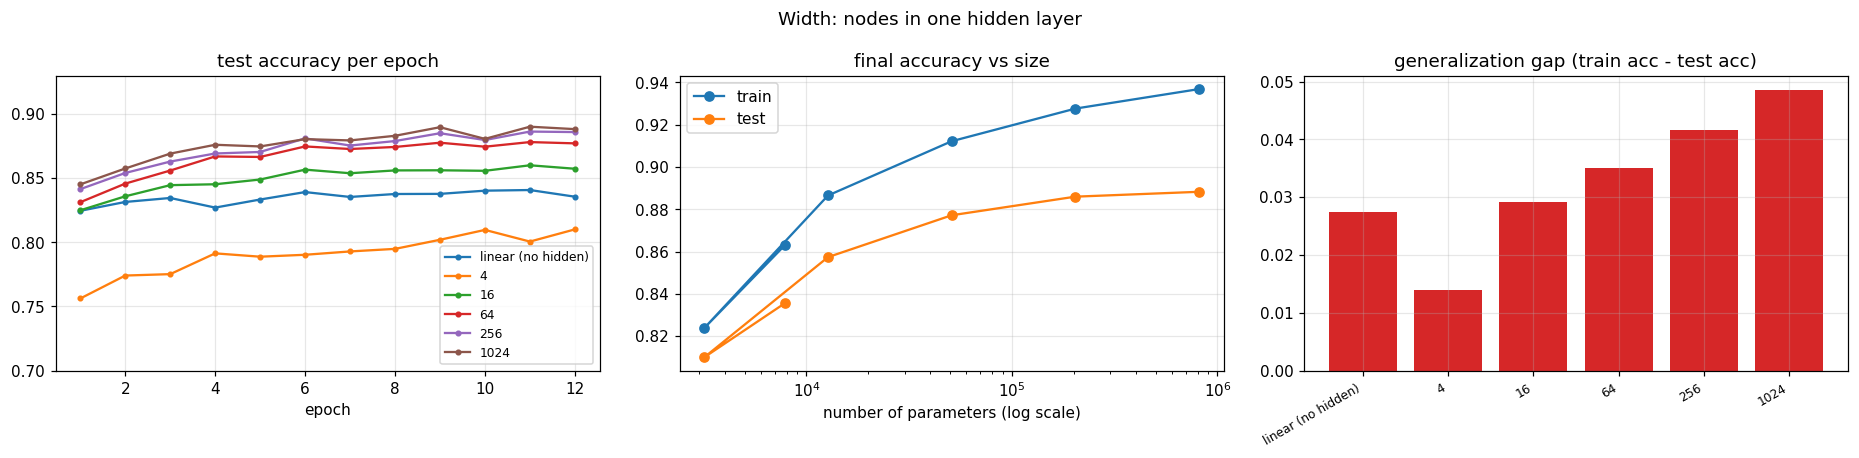

,params,train_acc,test_acc,gap,steps_to_memorize_64,train_time_s
network,,,,,,
linear (no hidden),7850,0.8630,0.8356,0.0274,24,20.5
4,3190,0.8240,0.8101,0.0139,213,20.7
16,12730,0.8866,0.8574,0.0291,54,20.9
64,50890,0.9122,0.8772,0.0350,48,24.9
256,203530,0.9276,0.8860,0.0416,43,40.1
1024,814090,0.9369,0.8883,0.0486,36,101.6


In [9]:
def plot_family(res, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    for name, r in res.items():
        ax[0].plot(range(1, len(r['test_acc']) + 1), r['test_acc'], marker='o', ms=3, label=name)
    ax[0].set_title('test accuracy per epoch'); ax[0].set_xlabel('epoch'); ax[0].set_ylim(0.7, 0.93); ax[0].legend(fontsize=8)

    names = list(res)
    params = [res[n]['params'] for n in names]
    ax[1].plot(params, [res[n]['train_acc'][-1] for n in names], marker='o', label='train')
    ax[1].plot(params, [res[n]['test_acc'][-1]  for n in names], marker='o', label='test')
    ax[1].set_xscale('log'); ax[1].set_xlabel('number of parameters (log scale)'); ax[1].set_title('final accuracy vs size'); ax[1].legend()

    ax[2].bar(range(len(names)), [res[n]['train_acc'][-1] - res[n]['test_acc'][-1] for n in names], color='C3')
    ax[2].set_xticks(range(len(names))); ax[2].set_xticklabels(names, rotation=30, ha='right', fontsize=8)
    ax[2].set_title('generalization gap (train acc - test acc)')
    fig.suptitle(title); plt.tight_layout(); plt.show()

def summary(res):
    rows = []
    for name, r in res.items():
        rows.append({'network': name, 'params': r['params'],
                     'train_acc': r['train_acc'][-1], 'test_acc': r['test_acc'][-1],
                     'gap': r['train_acc'][-1] - r['test_acc'][-1],
                     'steps_to_memorize_64': r['steps_to_memorize_64'], 'train_time_s': round(r['time'], 1)})
    return pd.DataFrame(rows).set_index('network').round(4)

plot_family(width_res, 'Width: nodes in one hidden layer')
display(summary(width_res))

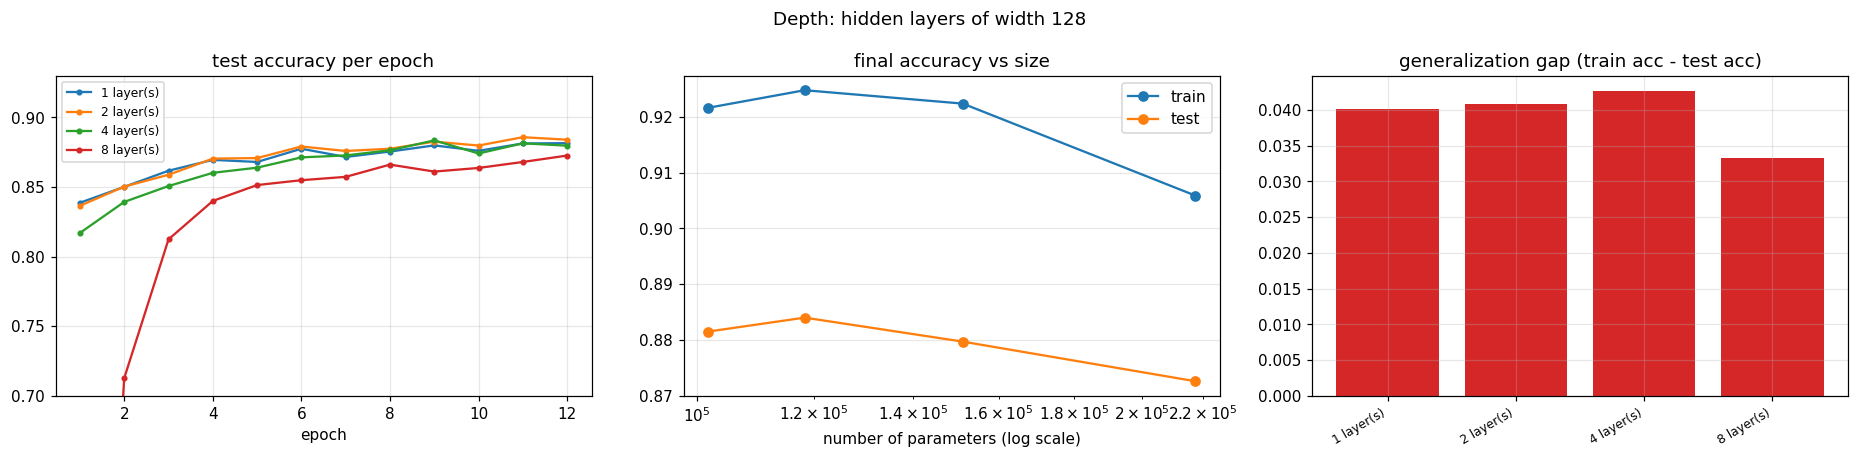

,params,train_acc,test_acc,gap,steps_to_memorize_64,train_time_s
network,,,,,,
1 layer(s),101770,0.9216,0.8815,0.0401,47.0,29.5
2 layer(s),118282,0.9248,0.8840,0.0407,65.0,32.6
4 layer(s),151306,0.9224,0.8797,0.0426,132.0,39.4
8 layer(s),217354,0.9059,0.8726,0.0333,NaN,54.3


In [10]:
plot_family(depth_res, 'Depth: hidden layers of width 128')
display(summary(depth_res))

## What to look for

**Width**
- A **linear** model (no hidden layer) already reaches the mid-80s. The first few hidden nodes give a big jump, and then each doubling gives less and less. Past a few hundred nodes there is almost no gain in test accuracy.
- A very **narrow** layer (4 nodes) is a bottleneck: all information about an image must squeeze through 4 numbers, so it underfits (train and test both low, small gap).
- Wider networks fit the training data better, and train accuracy pulls away from test accuracy, so the **gap** grows. More capacity means more ability to memorize.

**Depth**
- Going from 1 to 2 hidden layers helps little on Fashion-MNIST, and more layers usually give no further gain. They add parameters, training time, and possible optimization difficulty (an 8-layer net trained with plain SGD may train more slowly).
- For a task this simple, **width and depth are both past the point of diminishing returns** quickly. The extra capacity mostly shows up as a larger train/test gap.

**The memorization probe** (`steps_to_memorize_64`): bigger networks memorize 64 images in fewer steps (or at all, while the tiniest networks may never). It is a direct, cheap measure of *capacity*, and it connects Part 1 to Part 2: the tiny batch test not only catches bugs, it also tells you whether the model has enough capacity.

## Takeaways

1. **Before training on the full dataset, overfit one tiny batch.** The loss must go to about 0 with 100% accuracy. If not, debug the pipeline first (missing `step`/`backward`, wrong loss, labels not matching, bad learning rate).
2. A loss floor above zero (`double_softmax`) or a loss stuck near `ln(num_classes)` are classic signs of specific bugs.
3. **Width:** more nodes means more capacity, with diminishing returns. Too narrow means underfitting.
4. **Depth:** more layers is not automatically better. On simple data it adds cost without much gain.
5. **Capacity is a trade-off:** more capacity fits training data better but widens the train/test gap. Choose the *smallest* network that performs well on validation data.
6. Count parameters (`count_params`). It is a quick way to compare models fairly.

## Exercises
1. Run the tiny batch test with a **1,000-image** batch. Which networks can reach 100%? (This is a capacity test.)
2. **Random labels:** shuffle `ytr` once so labels have no relation to images, and try to memorize 512 of them. How large a network do you need? What does this say about capacity vs. learning real patterns?
3. Add one more bug of your own to `tiny_batch` (for example, forgetting `model.train()` with a Dropout layer, or using `nn.Sigmoid` as the last layer) and see if the test catches it.
4. Compare two networks with a **similar parameter count** but different shapes: `(512,)` vs `(128, 128, 128)`. Which is better?
5. Add `nn.Dropout(0.3)` to the widest network. Does the generalization gap shrink?
6. Plot test accuracy against **training time** instead of parameters. Where is the best trade-off?